# 02 — Understand the dataset and screen item coverage
 **Purpose:** check the integrated data and identify items with too few training records.
 **Saved:** `training_item_coverage.csv`, including the exclusion decision used by Notebook 03.
 Other summaries stay in this notebook. Save the notebook after running it to retain tables and plots for your report.

Only the selected experiment period is described. Outputs are isolated under `data/experiments/<experiment>/`.


In [1]:
import pandas as pd
import numpy as np
import json
import hashlib
import matplotlib.pyplot as plt
import pricecatcher_config as cfg
from importlib import reload
cfg = reload(cfg)
print("Experiment:", cfg.EXPERIMENT, "| Training cutoff:", cfg.TRAIN_END_DATE)

manifest_path = cfg.STAGE1_DIR / "source_manifest.json"
manifest = json.loads(manifest_path.read_text())
expected_months = pd.period_range(cfg.START_MONTH, cfg.END_MONTH, freq="M").astype(str).tolist()
if manifest["months"] != expected_months or manifest["selected_item_codes"] != cfg.SCOPE_ITEM_CODES:
    raise ValueError("Source scope changed. Rerun 01 before preparing experiments.")
# Link each stage to the same integration manifest and settings.
preparation = {**cfg.PREPARATION_SETTINGS,
               "source_manifest_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest()}
df = pd.read_parquet(cfg.STAGE1_COMBINED_PARQUET)
df["date"] = pd.to_datetime(df["date"])
df = df.loc[df["date"].between(pd.Timestamp(cfg.START_MONTH + "-01"),
                                  pd.Timestamp(cfg.EVALUATION_END_DATE))].copy()
print("Rows:", len(df), "| Period:", df["date"].min(), "to", df["date"].max())
print("Unique premises:", df["premise_code"].nunique())


Experiment: holdout | Training cutoff: 2025-12-31
Rows: 4731934 | Period: 2025-01-01 00:00:00 to 2026-06-30 00:00:00
Unique premises: 2558


## 1. Check variables, invalid prices and duplicate keys


In [2]:
overview = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "null_count": df.isna().sum(), "unique_values": df.nunique()})
invalid = df["price"].isna() | ~np.isfinite(df["price"]) | (df["price"] <= 0)
print("Invalid prices:", invalid.sum())
print("Duplicate keys:", df.duplicated(["date", "premise_code", "item_code"]).sum())
display(overview)


Invalid prices: 0
Duplicate keys: 0


,dtype,null_count,unique_values
date,datetime64[ms],0,515
state,string,0,16
district,string,0,169
premise_type,string,0,6
premise,string,0,2529
premise_code,Int64,0,2558
project_group,string,0,7
item_code,Int64,0,27
item,string,0,27
unit,string,0,3


## 2. Describe the dataset


,records
project_group,
Chicken,528201
Cooking Oil,174299
Eggs,946588
Flour,105562
Rice,71737
Sugar,162924
Vegetables,2742623


States: 16 | Districts: 169 | Premise types: 6 | Item codes: 27


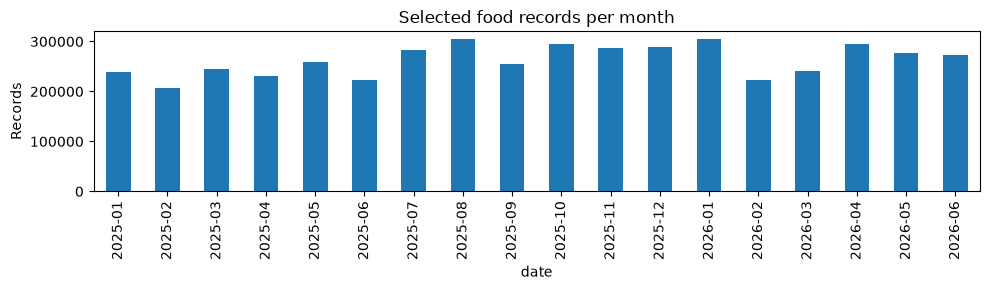

In [3]:
# Full-period counts describe scope; they do not select modelling settings.
display(df.groupby("project_group").size().rename("records").to_frame())
print("States:", df["state"].nunique(), "| Districts:", df["district"].nunique(),
      "| Premise types:", df["premise_type"].nunique(), "| Item codes:", df["item_code"].nunique())
monthly = df.groupby(df["date"].dt.to_period("M")).size()
monthly.plot.bar(figsize=(10, 3), title="Selected food records per month")
plt.ylabel("Records")
plt.tight_layout()
plt.show()


## 3. Screen items using training retail data only
 Exclude items below 5% of the median non-zero item count, and items with no valid training records. This is an item-level screening rule; Notebook 05 checks local weekly coverage separately. It does not guarantee every remaining local series is reliable.


In [4]:
training = df.loc[(df["date"] <= pd.Timestamp(cfg.TRAIN_END_DATE)) & ~invalid].copy()
if cfg.REMOVE_BORONG:
    training = training.loc[training["premise_type"] != "Borong"].copy()
if training.empty or not 0 < cfg.LOW_COVERAGE_RATIO < 1:
    raise ValueError("Check training dates and the low-coverage ratio.")
counts = training.groupby("item_code").size().reindex(cfg.SCOPE_ITEM_CODES, fill_value=0)
coverage_cutoff = float(counts.loc[counts > 0].median() * cfg.LOW_COVERAGE_RATIO)
item_coverage = counts.rename("training_records").reset_index()
item_coverage["project_group"] = item_coverage["item_code"].map(cfg.PROJECT_ITEM_MAP)
item_coverage["coverage_cutoff"] = coverage_cutoff
item_coverage["exclude_low_coverage"] = (item_coverage["training_records"] == 0) | (item_coverage["training_records"] < coverage_cutoff)
item_coverage["training_end"] = cfg.TRAIN_END_DATE
item_coverage["experiment"] = cfg.EXPERIMENT
item_coverage.to_csv(cfg.STAGE2_ITEM_COVERAGE_CSV, index=False)
print("Training-only item cutoff:", round(coverage_cutoff, 2))
print("Excluded item codes:", item_coverage.loc[item_coverage["exclude_low_coverage"], "item_code"].tolist())
display(item_coverage.loc[item_coverage["exclude_low_coverage"]])
print("Next: Notebook 03.")

(cfg.STAGE2_DIR / "preparation_settings.json").write_text(json.dumps(preparation, indent=2))


Training-only item cutoff: 3382.6
Excluded item codes: [992, 1581, 1582, 1593]


,item_code,training_records,project_group,coverage_cutoff,exclude_low_coverage,training_end,experiment
9,992,282,Rice,3382.6,True,2025-12-31,holdout
10,1581,2532,Rice,3382.6,True,2025-12-31,holdout
11,1582,2356,Rice,3382.6,True,2025-12-31,holdout
24,1593,1234,Flour,3382.6,True,2025-12-31,holdout


Next: Notebook 03.


1743

## 4. Training coverage by food group
Use training data for preparation decisions. Full-period descriptive counts above do not select settings. The 5% item rule is a project heuristic, not a guarantee of reliable local weeks.

In [5]:
display(training.groupby("project_group").agg(
    records=("price", "size"), items=("item_code", "nunique"),
    premises=("premise_code", "nunique"), observed_days=("date", "nunique")
))


,records,items,premises,observed_days
project_group,,,,
Chicken,349339,2,1658,348
Cooking Oil,108142,4,2064,119
Eggs,620176,6,2158,346
Flour,68886,2,2074,130
Rice,59924,4,916,262
Sugar,103251,2,2278,132
Vegetables,1805805,7,1919,348
